In [33]:
import pandas as pd
from pathlib import Path

files = sorted(Path("../data/raw").glob("seriea_*.csv"))
df = pd.concat([pd.read_csv(f).assign(Season=f.stem[-4:]) for f in files], ignore_index=True)
df = df[["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]].dropna()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, format="mixed")
df = df.sort_values("Date").reset_index(drop=True)
len(df)

C:\Users\Utente\AppData\Local\Temp\ipykernel_23692\229963635.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.concat([pd.read_csv(f).assign(Season=f.stem[-4:]) for f in files], ignore_index=True)


3910

In [34]:
K = 25
HOME_ADV = 50
ratings = {}
elo_home, elo_away, exp_list = [], [], []

for row in df.itertuples():
    rh = ratings.get(row.HomeTeam, 1500)
    ra = ratings.get(row.AwayTeam, 1500)
    exp_home = 1 / (1 + 10 ** ((ra - (rh + HOME_ADV)) / 400))

    elo_home.append(rh)
    elo_away.append(ra)
    exp_list.append(exp_home)

    score = {"H": 1, "D": 0.5, "A": 0}[row.FTR]
    ratings[row.HomeTeam] = rh + K * (score - exp_home)
    ratings[row.AwayTeam] = ra - K * (score - exp_home)

df["EloHome"] = elo_home
df["EloAway"] = elo_away
df["ExpHome"] = exp_list

In [35]:
attuali = df[df["Date"] >= "2026-07-01"]["HomeTeam"].unique()
pd.Series(ratings)[attuali].sort_values(ascending=False).round()

Inter         1828.0
Roma          1756.0
Milan         1702.0
Como          1701.0
Lazio         1695.0
Napoli        1681.0
Juventus      1676.0
Bologna       1624.0
Atalanta      1605.0
Fiorentina    1549.0
Cagliari      1537.0
Torino        1528.0
Genoa         1523.0
Frosinone     1507.0
Parma         1492.0
Sassuolo      1485.0
Udinese       1472.0
Lecce         1464.0
Venezia       1407.0
Monza         1370.0
dtype: float64

In [36]:
test = df[df["Date"] >= "2017-07-01"]
pred = test["ExpHome"].apply(lambda p: "H" if p >= 0.5 else "A")

acc_base = (test["FTR"] == "H").mean()
acc_elo = (pred == test["FTR"]).mean()
print(f"Baseline: {acc_base:.1%}   Elo: {acc_elo:.1%}")

Baseline: 41.4%   Elo: 53.6%


In [37]:
def calcola_elo(df, K, HOME_ADV):
    ratings = {}
    exp_list = []
    for row in df.itertuples():
        rh = ratings.get(row.HomeTeam, 1500)
        ra = ratings.get(row.AwayTeam, 1500)
        exp_home = 1 / (1 + 10 ** ((ra - (rh + HOME_ADV)) / 400))
        exp_list.append(exp_home)
        score = {"H": 1, "D": 0.5, "A": 0}[row.FTR]
        ratings[row.HomeTeam] = rh + K * (score - exp_home)
        ratings[row.AwayTeam] = ra - K * (score - exp_home)
    return pd.Series(exp_list, index=df.index)

def accuratezza(exp, risultati):
    pred = exp.apply(lambda p: "H" if p >= 0.5 else "A")
    return (pred == risultati).mean()

In [38]:
tuning = (df["Date"] >= "2017-07-01") & (df["Date"] < "2023-07-01")
test = df["Date"] >= "2023-07-01"

risultati = []
for K in [10, 15, 20, 25, 30, 40]:
    for H in [0, 25, 50, 75, 100]:
        exp = calcola_elo(df, K, H)
        acc = accuratezza(exp[tuning], df.loc[tuning, "FTR"])
        risultati.append({"K": K, "HOME_ADV": H, "acc_tuning": acc})

tab = pd.DataFrame(risultati).sort_values("acc_tuning", ascending=False)
tab.head()

,K,HOME_ADV,acc_tuning
11,20,25,0.542982
16,25,25,0.540789
21,30,25,0.540789
26,40,25,0.540351
17,25,50,0.539912


In [39]:
best = tab.iloc[0]
exp = calcola_elo(df, best["K"], best["HOME_ADV"])

acc_test = accuratezza(exp[test], df.loc[test, "FTR"])
base_test = (df.loc[test, "FTR"] == "H").mean()

print(f"Parametri scelti: K={best['K']:.0f}, HOME_ADV={best['HOME_ADV']:.0f}")
print(f"Test → Baseline: {base_test:.1%}   Elo: {acc_test:.1%}")

Parametri scelti: K=20, HOME_ADV=25
Test → Baseline: 40.7%   Elo: 53.0%


FTR         A      D      H
Season                     
1617    0.305  0.211  0.484
1718    0.350  0.218  0.432
1819    0.279  0.284  0.437
1920    0.361  0.224  0.416
2021    0.337  0.255  0.408
2122    0.353  0.258  0.389
2223    0.313  0.263  0.424
2324    0.287  0.295  0.418
2425    0.318  0.284  0.397
2526    0.350  0.261  0.389
2627    0.364  0.173  0.464


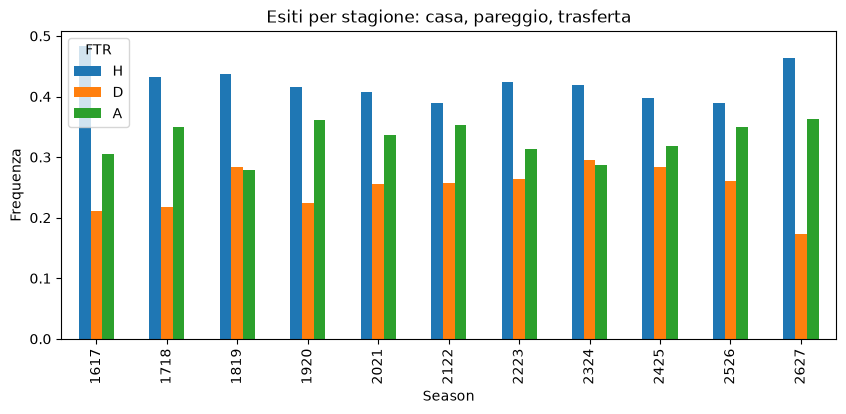

In [40]:
import matplotlib.pyplot as plt

esiti = df.groupby("Season")["FTR"].value_counts(normalize=True).unstack()
print(esiti.round(3))

esiti[["H", "D", "A"]].plot(kind="bar", figsize=(10, 4))
plt.ylabel("Frequenza")
plt.title("Esiti per stagione: casa, pareggio, trasferta")
plt.show()

In [41]:
def calcola_elo_reg(df, K, HOME_ADV, REG):
    ratings = {}
    exp_list = []
    stagione = None
    for row in df.itertuples():
        if row.Season != stagione:
            stagione = row.Season
            for team in ratings:
                ratings[team] = (1 - REG) * ratings[team] + REG * 1500
        rh = ratings.get(row.HomeTeam, 1500)
        ra = ratings.get(row.AwayTeam, 1500)
        exp_home = 1 / (1 + 10 ** ((ra - (rh + HOME_ADV)) / 400))
        exp_list.append(exp_home)
        score = {"H": 1, "D": 0.5, "A": 0}[row.FTR]
        ratings[row.HomeTeam] = rh + K * (score - exp_home)
        ratings[row.AwayTeam] = ra - K * (score - exp_home)
    return pd.Series(exp_list, index=df.index)

In [42]:
risultati = []
for K in [15, 20, 25, 30]:
    for H in [0, 25, 50, 75]:
        for REG in [0, 0.1, 0.2, 0.3, 0.4]:
            exp = calcola_elo_reg(df, K, H, REG)
            acc = accuratezza(exp[tuning], df.loc[tuning, "FTR"])
            risultati.append({"K": K, "HOME_ADV": H, "REG": REG, "acc_tuning": acc})

tab_reg = pd.DataFrame(risultati).sort_values("acc_tuning", ascending=False)
tab_reg.head()

,K,HOME_ADV,REG,acc_tuning
25,20,25,0.0,0.542982
45,25,25,0.0,0.540789
65,30,25,0.0,0.540789
30,20,50,0.0,0.539912
66,30,25,0.1,0.539912


In [43]:
best = tab_reg.iloc[0]
exp = calcola_elo_reg(df, best["K"], best["HOME_ADV"], best["REG"])
acc_test = accuratezza(exp[test], df.loc[test, "FTR"])
print(f"K={best['K']:.0f}, HOME_ADV={best['HOME_ADV']:.0f}, REG={best['REG']}")
print(f"Test → Elo con regressione: {acc_test:.1%}   (prima: 53,0%)")

K=20, HOME_ADV=25, REG=0.0
Test → Elo con regressione: 53.0%   (prima: 53,0%)
